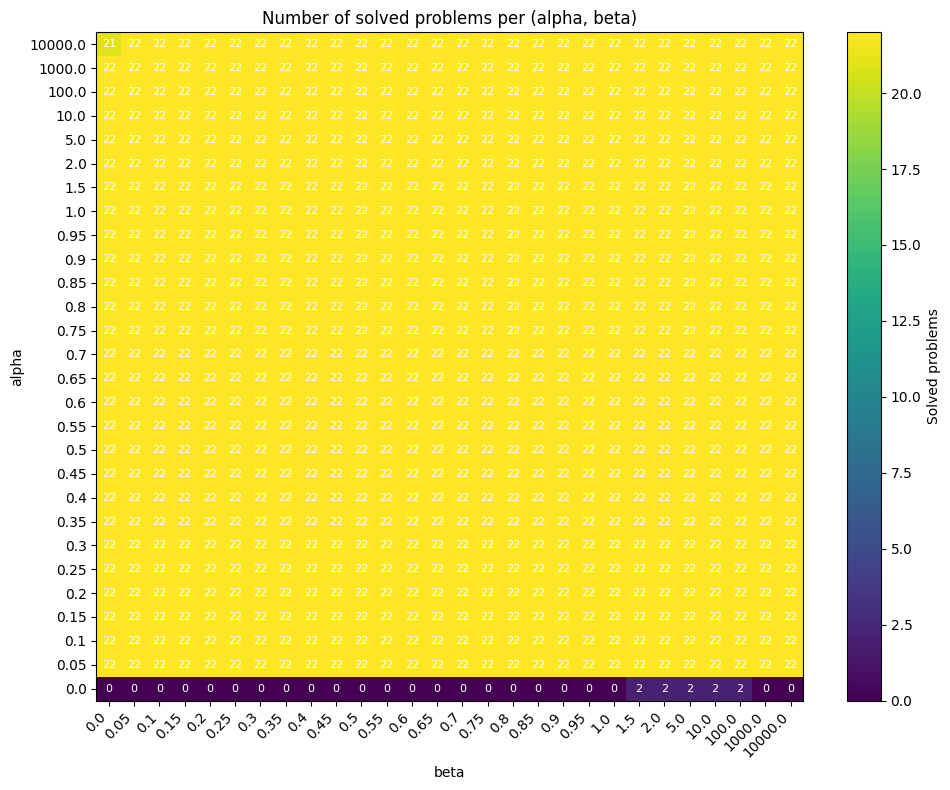

,alpha,beta,solved_count
28,0.05,0.00,22
29,0.05,0.05,22
30,0.05,0.10,22
31,0.05,0.15,22
32,0.05,0.20,22
33,0.05,0.25,22
34,0.05,0.30,22
35,0.05,0.35,22
36,0.05,0.40,22
37,0.05,0.45,22


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Locate project root from this notebook location
project_root = Path.cwd()
if project_root.name == "evaluation":
    project_root = project_root.parents[3]
elif (project_root / "tower_of_london_plots").exists() is False:
    project_root = Path(r"c:/Users/Michael Migacev/Desktop/UNI/Wirklich_UNI/AICON/master-thesis-tol/master-thesis-tol")

data_dir = project_root / "tower_of_london_plots" / "gridsearch_0-10000"
csv_files = sorted(data_dir.glob("gridsearch_bmsa*.csv"))

if not csv_files:
    raise FileNotFoundError(f"No matching CSVs found in: {data_dir}")

# Read all CSVs; each file corresponds to one alpha-beta setting
frames = []
for file in csv_files:
    df = pd.read_csv(file)
    if "alpha" not in df.columns or "beta" not in df.columns:
        raise ValueError(f"CSV missing alpha/beta columns: {file.name}")
    if "finished" not in df.columns:
        raise ValueError(f"CSV missing finished column: {file.name}")
    df["source_file"] = file.name
    frames.append(df)

all_results = pd.concat(frames, ignore_index=True)

# Count solved problems (finished==True) per alpha, beta
solved_grid = (
    all_results
    .groupby(["alpha", "beta"], as_index=False)["finished"]
    .sum()
    .rename(columns={"finished": "solved_count"})
)

pivot = solved_grid.pivot(index="alpha", columns="beta", values="solved_count")
pivot = pivot.sort_index().sort_index(axis=1)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(pivot.values, aspect="auto", origin="lower", cmap="viridis")

ax.set_xticks(np.arange(len(pivot.columns)))
ax.set_yticks(np.arange(len(pivot.index)))
ax.set_xticklabels([str(v) for v in pivot.columns], rotation=45, ha="right")
ax.set_yticklabels([str(v) for v in pivot.index])

ax.set_xlabel("beta")
ax.set_ylabel("alpha")
ax.set_title("Number of solved problems per (alpha, beta)")

# Annotate each grid cell with solved count
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        value = int(pivot.iloc[i, j]) if not pd.isna(pivot.iloc[i, j]) else 0
        ax.text(j, i, str(value), ha="center", va="center", color="white", fontsize=8)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Solved problems")

plt.tight_layout()
plt.show()

solved_grid.sort_values(["solved_count", "alpha", "beta"], ascending=[False, True, True]).head(10)

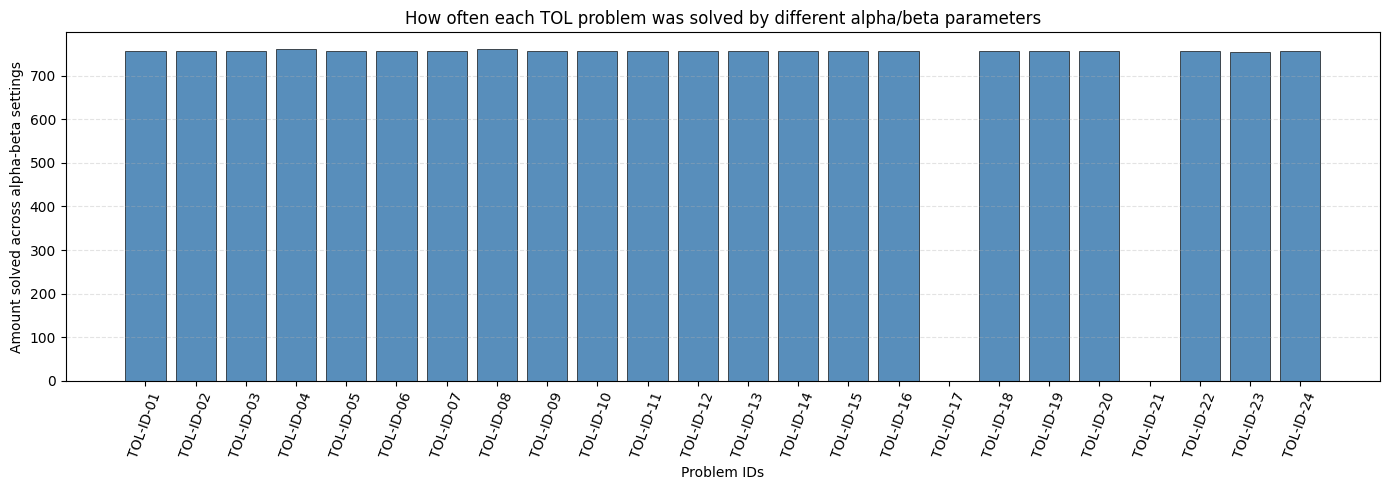

,tol_id,problem,num_parameter_settings_solved
0,TOL-ID-01,54->31,756
1,TOL-ID-02,42->23,756
2,TOL-ID-03,34->13,756
3,TOL-ID-04,12->65,761
4,TOL-ID-05,55->41,756
5,TOL-ID-06,16->24,756
6,TOL-ID-07,25->32,756
7,TOL-ID-08,36->15,761
8,TOL-ID-09,33->11,756
9,TOL-ID-10,53->13,756


In [2]:
import matplotlib.pyplot as plt
import numpy as np

if "all_results" not in globals():
    raise RuntimeError("Run Cell 1 first so 'all_results' is available.")

required_cols = {"init", "goal", "finished"}
missing = required_cols - set(all_results.columns)
if missing:
    raise ValueError(f"Missing required columns in all_results: {missing}")

# Preserve original problem order (as generated in each run)
problem_order = (
    all_results[["init", "goal"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)

problem_order["tol_id"] = [f"TOL-ID-{i:02d}" for i in range(1, len(problem_order) + 1)]
problem_order["problem"] = problem_order["init"].astype(str) + "->" + problem_order["goal"].astype(str)

problem_success_counts = (
    all_results
    .assign(problem=all_results["init"].astype(str) + "->" + all_results["goal"].astype(str))
    .groupby("problem", as_index=False)["finished"]
    .sum()
    .rename(columns={"finished": "num_parameter_settings_solved"})
)

plot_df = problem_order[["tol_id", "problem"]].merge(
    problem_success_counts,
    on="problem",
    how="left",
).fillna({"num_parameter_settings_solved": 0})

plot_df["num_parameter_settings_solved"] = plot_df["num_parameter_settings_solved"].astype(int)

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(plot_df))
ax.bar(
    x,
    plot_df["num_parameter_settings_solved"],
    color="steelblue",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.9,
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df["tol_id"], rotation=70)
ax.set_xlabel("Problem IDs")
ax.set_ylabel("Amount solved across alpha-beta settings")
ax.set_title("How often each TOL problem was solved by different alpha/beta parameters")
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

# Helpful legend table to map IDs back to init->goal
plot_df[["tol_id", "problem", "num_parameter_settings_solved"]]

## Average Moves to Success per Problem

This cell shows the average number of moves required to solve each problem across all successful runs (alpha/beta parameter combinations).

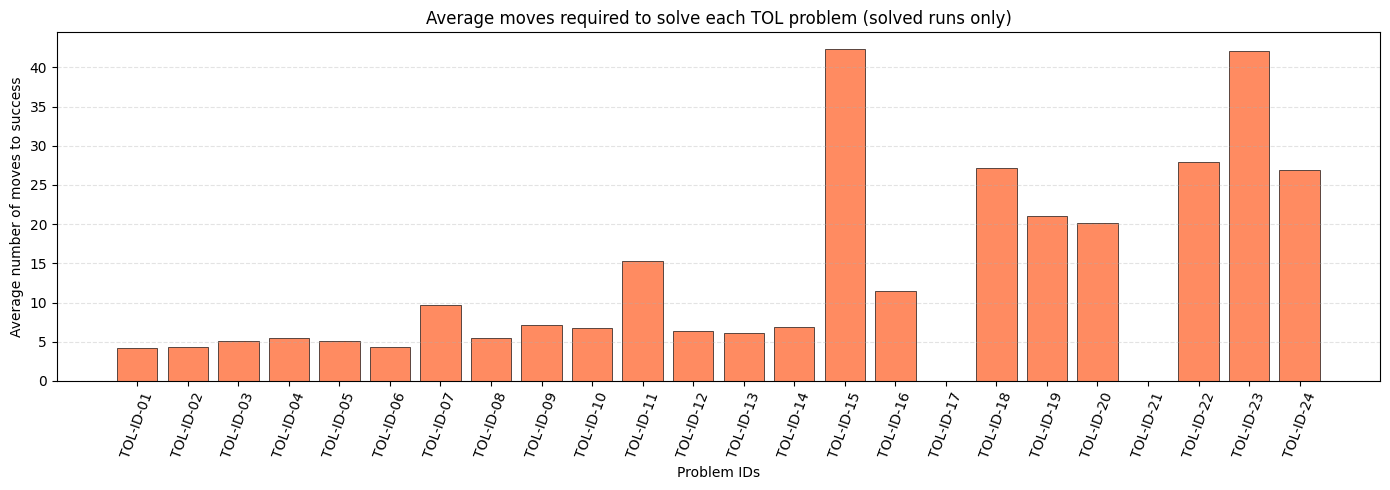

,tol_id,problem,avg_moves
0,TOL-ID-01,54->31,4.267196
1,TOL-ID-02,42->23,4.366402
2,TOL-ID-03,34->13,5.112434
3,TOL-ID-04,12->65,5.504599
4,TOL-ID-05,55->41,5.104497
5,TOL-ID-06,16->24,4.291005
6,TOL-ID-07,25->32,9.646825
7,TOL-ID-08,36->15,5.475690
8,TOL-ID-09,33->11,7.167989
9,TOL-ID-10,53->13,6.727513


In [3]:
import matplotlib.pyplot as plt
import numpy as np

if "problem_order" not in globals():
    raise RuntimeError("Run Cell 2 first so 'problem_order' is available.")

if "all_results" not in globals():
    raise RuntimeError("Run Cell 1 first so 'all_results' is available.")

required_cols = {"finished", "num_moves"}
missing = required_cols - set(all_results.columns)
if missing:
    raise ValueError(f"Missing required columns in all_results: {missing}")

# Filter for solved problems only
solved_results = all_results[all_results["finished"] == True].copy()

if solved_results.empty:
    raise ValueError("No solved problems found. Check the 'finished' column.")

# Create problem column
solved_results["problem"] = solved_results["init"].astype(str) + "->" + solved_results["goal"].astype(str)

# Compute average moves per problem (only for solved problems)
avg_moves_per_problem = (
    solved_results
    .groupby("problem", as_index=False)["num_moves"]
    .mean()
    .rename(columns={"num_moves": "avg_moves"})
)

# Merge with problem_order to get tol_id and maintain order
plot_df_moves = problem_order[["tol_id", "problem"]].merge(
    avg_moves_per_problem,
    on="problem",
    how="left",
)

# Problems with no solved runs will have NaN; fill with 0 for visualization clarity
plot_df_moves["avg_moves"] = plot_df_moves["avg_moves"].fillna(0)

# Create bar chart
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(plot_df_moves))
ax.bar(
    x,
    plot_df_moves["avg_moves"],
    color="coral",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.9,
)

ax.set_xticks(x)
ax.set_xticklabels(plot_df_moves["tol_id"], rotation=70)
ax.set_xlabel("Problem IDs")
ax.set_ylabel("Average number of moves to success")
ax.set_title("Average moves required to solve each TOL problem (solved runs only)")
ax.grid(axis="y", linestyle="--", alpha=0.35)

plt.tight_layout()
plt.show()

# Display the data with legend
plot_df_moves[["tol_id", "problem", "avg_moves"]]

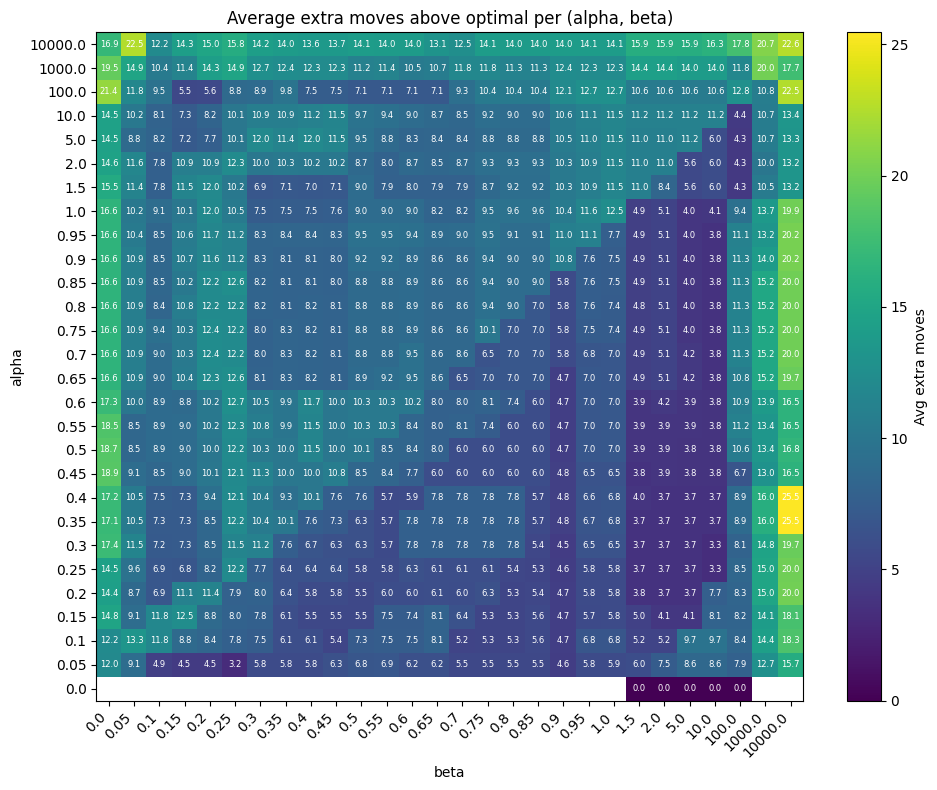

beta,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,...,0.90,0.95,1.00,1.50,2.00,5.00,10.00,100.00,1000.00,10000.00
alpha,,,,,,,,,,,,,,,,,,,,,
0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN
0.05,11.954545,9.136364,4.863636,4.454545,4.454545,3.227273,5.772727,5.772727,5.772727,6.318182,...,4.636364,5.772727,5.863636,6.000000,7.454545,8.636364,8.636364,7.863636,12.727273,15.727273
0.10,12.181818,13.318182,11.772727,8.818182,8.409091,7.772727,7.545455,6.090909,6.090909,5.363636,...,4.681818,6.772727,6.772727,5.181818,5.181818,9.727273,9.681818,8.409091,14.363636,18.318182
0.15,14.818182,9.090909,11.818182,12.500000,8.818182,8.045455,7.818182,6.090909,5.545455,5.545455,...,4.681818,5.727273,5.818182,4.954545,4.090909,4.090909,8.090909,8.227273,14.090909,18.090909
0.20,14.409091,8.681818,6.863636,11.136364,11.409091,7.863636,8.000000,6.363636,5.818182,5.818182,...,4.681818,5.772727,5.772727,3.772727,3.681818,3.681818,7.681818,8.272727,14.954545,20.045455
0.25,14.500000,9.590909,6.863636,6.772727,8.227273,12.227273,7.727273,6.363636,6.363636,6.363636,...,4.590909,5.772727,5.772727,3.681818,3.681818,3.681818,3.318182,8.454545,14.954545,19.954545
0.30,17.363636,11.500000,7.181818,7.272727,8.500000,11.500000,11.227273,7.590909,6.727273,6.272727,...,4.500000,6.545455,6.545455,3.681818,3.681818,3.681818,3.318182,8.090909,14.772727,19.681818
0.35,17.136364,10.500000,7.272727,7.272727,8.500000,12.227273,10.409091,10.136364,7.590909,7.318182,...,4.772727,6.681818,6.818182,3.681818,3.681818,3.681818,3.681818,8.909091,15.954545,25.454545
0.40,17.227273,10.500000,7.545455,7.272727,9.409091,12.136364,10.409091,9.318182,10.136364,7.590909,...,4.772727,6.590909,6.818182,3.954545,3.681818,3.681818,3.681818,8.909091,15.954545,25.454545


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- Import data (same pattern as Cell 1) ---
project_root = Path.cwd()
if project_root.name == "evaluation":
    project_root = project_root.parents[3]
elif (project_root / "tower_of_london_plots").exists() is False:
    project_root = Path(r"c:/Users/Michael Migacev/Desktop/UNI/Wirklich_UNI/AICON/master-thesis-tol/master-thesis-tol")

data_dir = project_root / "tower_of_london_plots" / "gridsearch_0-10000"
csv_files = sorted(data_dir.glob("gridsearch_bmsa*.csv"))

frames = []
for file in csv_files:
    df = pd.read_csv(file)
    df["source_file"] = file.name
    frames.append(df)

all_results = pd.concat(frames, ignore_index=True)

# --- Identify TOL problem ID from row order (same as before) ---
problem_order = (
    all_results[["init", "goal"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)
problem_order["tol_id"] = problem_order.index + 1  # 1-based TOL problem ID

# --- Map each problem to its optimal move count ---
# Problems 1-8: 4 optimal moves, 9-16: 5, 17-24: 6
def get_optimal_moves(tol_id):
    if tol_id <= 8:
        return 4
    elif tol_id <= 16:
        return 5
    else:
        return 6

# --- Filter to solved problems only ---
solved = all_results[all_results["finished"] == True].copy()

# Map each row to its TOL problem ID
init_goal_to_id = dict(zip(
    zip(problem_order["init"], problem_order["goal"]),
    problem_order["tol_id"]
))
solved["tol_id"] = solved.apply(
    lambda r: init_goal_to_id[(r["init"], r["goal"])], axis=1
)

# Calculate additional moves (above optimal)
solved["optimal_moves"] = solved["tol_id"].apply(get_optimal_moves)
solved["extra_moves"] = solved["num_moves"] - solved["optimal_moves"]

# --- Average extra moves per (alpha, beta) across all solved problems ---
avg_extra = (
    solved
    .groupby(["alpha", "beta"], as_index=False)["extra_moves"]
    .mean()
    .rename(columns={"extra_moves": "avg_extra_moves"})
)

# Pivot into grid
pivot = avg_extra.pivot(index="alpha", columns="beta", values="avg_extra_moves")
pivot = pivot.sort_index().sort_index(axis=1)

# --- Plot as heatmap (same style as Cell 1) ---
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(pivot.values, aspect="auto", origin="lower", cmap="viridis")

ax.set_xticks(np.arange(len(pivot.columns)))
ax.set_yticks(np.arange(len(pivot.index)))
ax.set_xticklabels([str(v) for v in pivot.columns], rotation=45, ha="right")
ax.set_yticklabels([str(v) for v in pivot.index])

ax.set_xlabel("beta")
ax.set_ylabel("alpha")
ax.set_title("Average extra moves above optimal per (alpha, beta)")

# Annotate each grid cell
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.1f}", ha="center", va="center", color="white", fontsize=6)

plt.colorbar(im, ax=ax, label="Avg extra moves")
plt.tight_layout()
plt.show()

# Display the pivot table
pivot
